In [1]:
# Import libraries for data preprocessing
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Import libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# Import libraries for data analysis + visualization
import scipy.stats as stats
import matplotlib.pyplot as plt

In [2]:
# Loading dataset
df = pd.read_csv("mcs_ds_edited_iter_shuffled.csv")
df.head()

,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


In [ ]:
# Split into x and y where x is the first 4 columns and y is ale
x = df.iloc[:, :4]
y = df['ale']


In [4]:
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(85, 4)
(22, 4)
(85,)
(22,)


Normality test statistic: 7.2997
p-value: 0.02599
Reject normality at the 5% significance level.


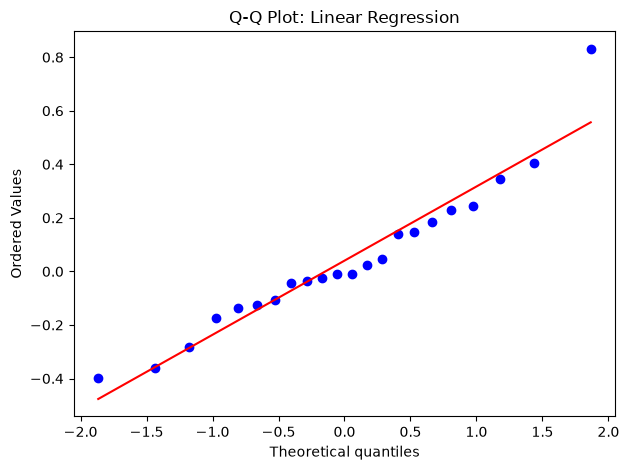

In [5]:
# Linear Regression
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict y-values and calculate residuals
y_lr_pred = lr_model.predict(X_test)
lr_residuals = y_test.to_numpy() - y_lr_pred

# Test residuals for normality
statistic, p_value = stats.normaltest(lr_residuals)

# Return results of test
print(f"Normality test statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject normality at the 5% significance level.")
else:
    print("Fail to reject normality at the 5% significance level.")

# Generate a Q-Q plot
plt.figure()
stats.probplot(lr_residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot: Linear Regression")
plt.tight_layout()
plt.show()

Normality test statistic: 2.7020
p-value: 0.259
Fail to reject normality at the 5% significance level.


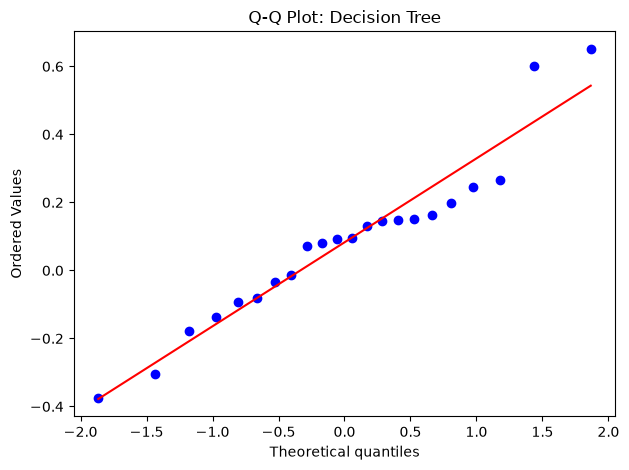

In [6]:
# Decision Tree
dt_model = DecisionTreeRegressor()

# Train the model
dt_model.fit(X_train, y_train)

# Predict y-values and calculate residuals
y_dt_pred = dt_model.predict(X_test)
dt_residuals = y_test.to_numpy() - y_dt_pred

# Test residuals for normality
statistic, p_value = stats.normaltest(dt_residuals)

# Return results of test
print(f"Normality test statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject normality at the 5% significance level.")
else:
    print("Fail to reject normality at the 5% significance level.")

# Generate a Q-Q plot
plt.figure()
stats.probplot(dt_residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot: Decision Tree")
plt.tight_layout()
plt.show()

Normality test statistic: 0.1111
p-value: 0.946
Fail to reject normality at the 5% significance level.


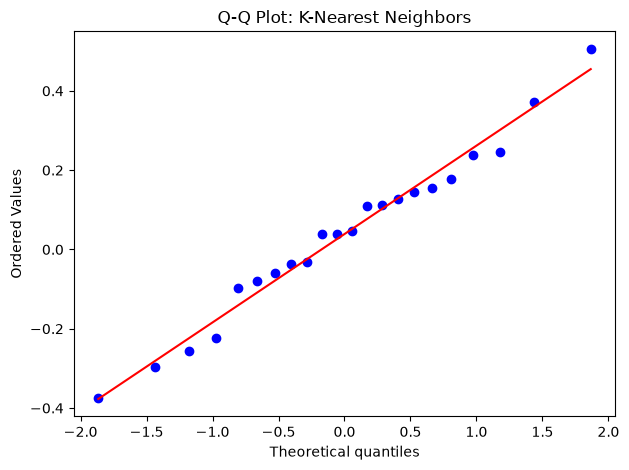

In [7]:
# K-Nearest Neighbors
knn_model = KNeighborsRegressor()

# Train the model
knn_model.fit(X_train, y_train)

# Predict y-values and calculate residuals
y_knn_pred = knn_model.predict(X_test)
knn_residuals = y_test.to_numpy() - y_knn_pred

# Test residuals for normality
statistic, p_value = stats.normaltest(knn_residuals)

# Return results of test
print(f"Normality test statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject normality at the 5% significance level.")
else:
    print("Fail to reject normality at the 5% significance level.")

# Generate a Q-Q plot
plt.figure()
stats.probplot(knn_residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot: K-Nearest Neighbors")
plt.tight_layout()
plt.show()

Normality test statistic: 11.0901
p-value: 0.003907
Reject normality at the 5% significance level.


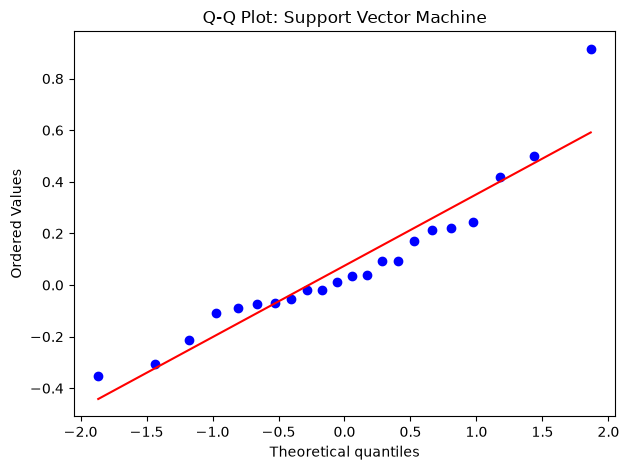

In [8]:
# Support Vector Machine
svm_model = make_pipeline(StandardScaler(),SVR(kernel='linear'))
# Train the model
svm_model.fit(X_train, y_train)

# Predict y-values and calculate residuals
y_svm_pred = svm_model.predict(X_test)
svm_residuals = y_test.to_numpy() - y_svm_pred

# Test residuals for normality
statistic, p_value = stats.normaltest(svm_residuals)

# Return results of test
print(f"Normality test statistic: {statistic:.4f}")
print(f"p-value: {p_value:.4g}")

if p_value < 0.05:
    print("Reject normality at the 5% significance level.")
else:
    print("Fail to reject normality at the 5% significance level.")

# Generate a Q-Q plot
plt.figure()
stats.probplot(svm_residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot: Support Vector Machine")
plt.tight_layout()
plt.show()